<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A06_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

**Виконав: Точенюк Ярослав, група 4-9.**

In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
for module, package in [('imblearn','imbalanced-learn'),('kagglehub','kagglehub'),('xgboost','xgboost'),('lightgbm','lightgbm'),('catboost','catboost')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')


**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
USE_UPLOAD = False
filename = 'diabetes_prediction_dataset.csv'
if USE_UPLOAD:
    from google.colab import files
    if not Path(filename).exists():
        files.upload()


In [3]:
if USE_UPLOAD:
    df = pd.read_csv(filename)
    display(df.head())


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
if not USE_UPLOAD:
    if Path(filename).exists():
        csv_path = Path(filename)
    else:
        import kagglehub
        folder = Path(kagglehub.dataset_download('iammustafatz/diabetes-prediction-dataset'))
        matches = list(folder.rglob(filename))
        if not matches:
            raise FileNotFoundError(filename)
        csv_path = matches[0]
    print('Джерело:', csv_path)


Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Джерело: /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv


In [5]:
if not USE_UPLOAD:
    df = pd.read_csv(csv_path)
required = {'gender','age','hypertension','heart_disease','smoking_history','bmi','HbA1c_level','blood_glucose_level','diabetes'}
assert required.issubset(df.columns), 'Невідповідні стовпці CSV'
assert set(df['diabetes'].unique()) == {0, 1}, 'Очікуються два класи 0 і 1'
display(df.head())
print('Розмір:', df.shape)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Розмір: (100000, 9)


Вивести інформацію про датасет

In [6]:
df.info()
print('Категоріальні ознаки:', df.select_dtypes(exclude='number').columns.tolist())
print('Числові ознаки:', df.select_dtypes(include='number').columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
Категоріальні ознаки: ['gender', 'smoking_history']
Числові ознаки: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


Провести дослідження категоріальних ознак

In [7]:
display(df['gender'].value_counts(dropna=False))

,count
gender,
Female,58552
Male,41430
Other,18


In [8]:
display(df['smoking_history'].value_counts(dropna=False))

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [9]:
display(df.head(10))

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


Вивести типи даних

In [10]:
display(df.dtypes)

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
display(df['diabetes'].value_counts())
print('Частки класів, %:')
display(df['diabetes'].value_counts(normalize=True)*100)
print('Висновок: співвідношення більшого класу до меншого:', round(df['diabetes'].value_counts().max()/df['diabetes'].value_counts().min(),2))

,count
diabetes,
0,91500
1,8500


Частки класів, %:


,proportion
diabetes,
0,91.5
1,8.5


Висновок: співвідношення більшого класу до меншого: 10.76


Висновок: визначте за результатом, чи є дисбаланс класів.

Числовий висновок виводиться в попередній комірці.

Перевірити наявність пропущених даних


In [12]:
display(df.isnull().sum())

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [14]:
df = df.drop_duplicates().reset_index(drop=True)
assert not df.duplicated().any()

In [15]:
display(df.head())
print(df.shape)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


(96146, 9)


Ще раз перевірити баланс цільової змінної

In [16]:
display(df['diabetes'].value_counts())

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


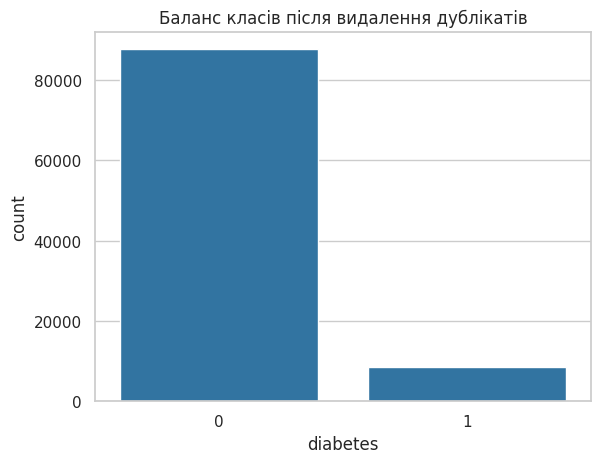

In [17]:
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Баланс класів після видалення дублікатів')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score
from sklearn.base import clone
from imblearn.over_sampling import SMOTE

In [19]:
X = df.drop(columns='diabetes')
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
assert not set(X_train.index).intersection(X_test.index)
print('Train:', X_train.shape, 'Test:', X_test.shape)
original_test_index = X_test.index.copy()
original_y_test = y_test.copy()

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
X_train = pd.get_dummies(X_train, columns=['gender','smoking_history'], dtype=float)
X_test = pd.get_dummies(X_test, columns=['gender','smoking_history'], dtype=float).reindex(columns=X_train.columns, fill_value=0)
assert X_train.columns.equals(X_test.columns)

In [21]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
target_corr = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
display(target_corr)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_No Info,-0.113053
smoking_history_former,0.096162
gender_Male,0.040650
gender_Female,-0.040533


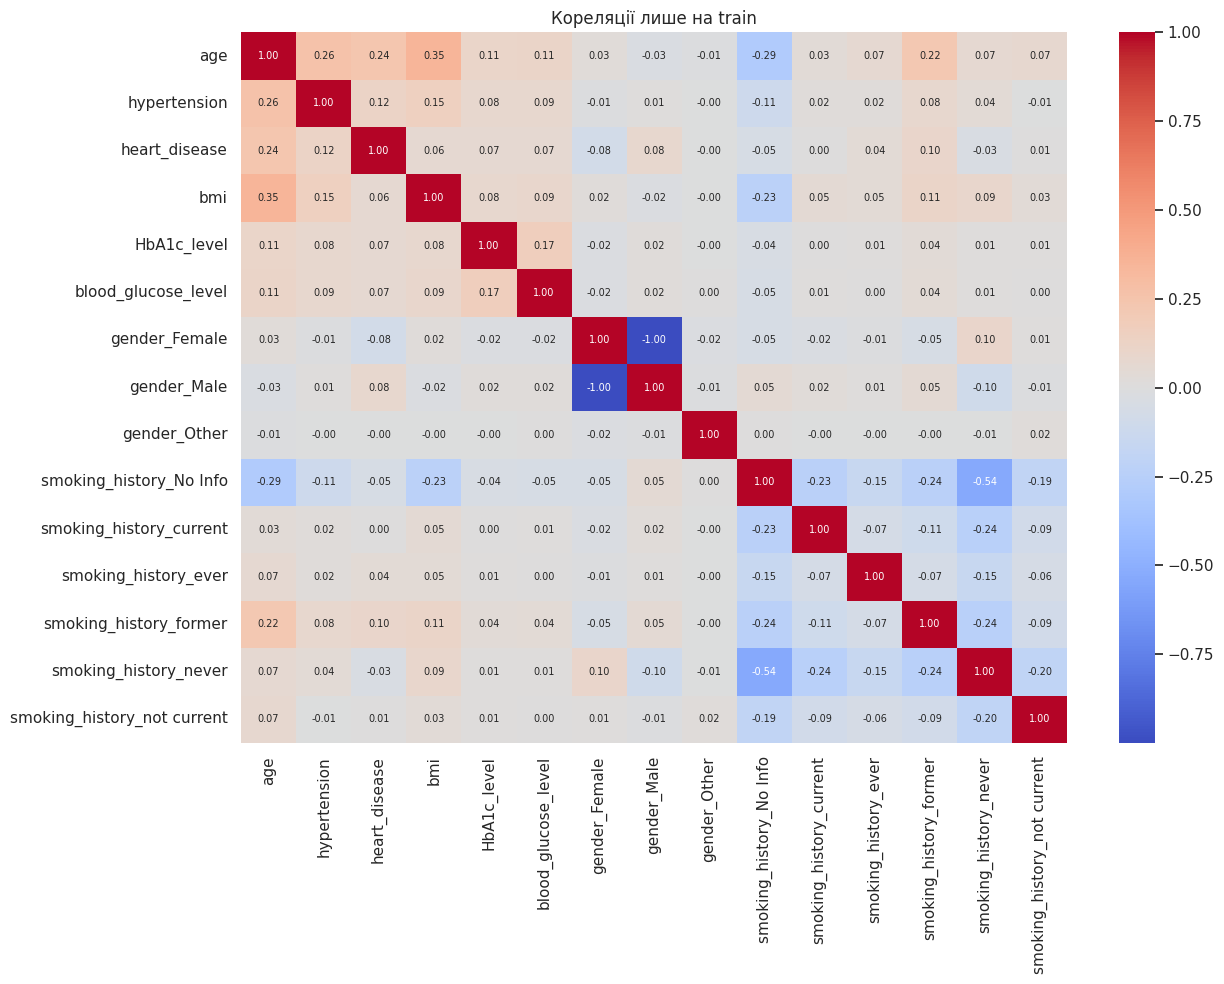

Пари з |r| >= 0.8:


,,0
gender_Female,gender_Male,-0.999626


Найбільші за модулем кореляції з ціллю:


,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649


Ознаки залишаємо: кореляція сама по собі не є підставою для вилучення; категоріальні індикатори можуть бути залежними.


In [23]:
corr = X_train.corr()
plt.figure(figsize=(13,10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size':7})
plt.title('Кореляції лише на train'); plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape,dtype=bool),k=1)).stack()
print('Пари з |r| >= 0.8:'); display(pairs[pairs.abs()>=0.8])
print('Найбільші за модулем кореляції з ціллю:'); display(target_corr.head(3))
print('Ознаки залишаємо: кореляція сама по собі не є підставою для вилучення; категоріальні індикатори можуть бути залежними.')

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

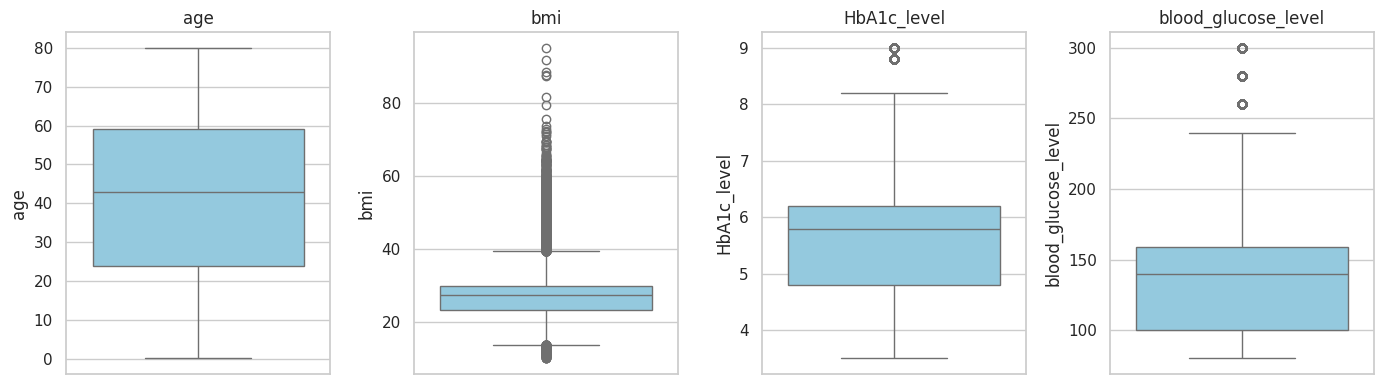

In [24]:
continuous_cols = ['age','bmi','HbA1c_level','blood_glucose_level']
fig, axes = plt.subplots(1,4,figsize=(14,4))
for col, ax in zip(continuous_cols,axes):
    sns.boxplot(y=X_train[col],ax=ax,color='skyblue'); ax.set_title(col)
plt.tight_layout(); plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
q1, q3 = X_train[continuous_cols].quantile(.25), X_train[continuous_cols].quantile(.75)
iqr = q3-q1
lower, upper = q1-1.5*iqr, q3+1.5*iqr
outliers = ((X_train[continuous_cols]<lower)|(X_train[continuous_cols]>upper)).sum()
display(pd.DataFrame({'Нижня межа':lower,'Верхня межа':upper,'Кількість поза межами':outliers}))

,Нижня межа,Верхня межа,Кількість поза межами
age,-28.5,111.50,0
bmi,13.7,39.54,4244
HbA1c_level,2.7,8.30,1041
blood_glucose_level,11.5,247.50,1598


Перевірити асиметрію розподілів ознак **на train**

In [26]:
display(X_train[continuous_cols].skew())

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [27]:
display(pd.DataFrame({'train':X_train.isna().sum(),'test':X_test.isna().sum()}))
assert not X_train.isna().any().any() and not X_test.isna().any().any(), 'CSV містить пропуски; перевірте оригінальний файл'
print('Train: баланс класів'); display(y_train.value_counts())
print('Найсильніша кореляція:', target_corr.index[0], round(target_corr.iloc[0],3))
print('Викиди не вилучалися; тестова вибірка не змінювалася.')

,train,test
age,0,0
hypertension,0,0
heart_disease,0,0
bmi,0,0
HbA1c_level,0,0
blood_glucose_level,0,0
gender_Female,0,0
gender_Male,0,0
gender_Other,0,0
smoking_history_No Info,0,0


Train: баланс класів


,count
diabetes,
0,70130
1,6786


Найсильніша кореляція: blood_glucose_level 0.423
Викиди не вилучалися; тестова вибірка не змінювалася.


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert np.allclose(X_train_scaled.mean(axis=0),0,atol=1e-8)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled,y_train)
display(pd.DataFrame({'До SMOTE':y_train.value_counts(),'Після SMOTE':pd.Series(y_train_balanced).value_counts()}))
assert pd.Series(y_train_balanced).value_counts().nunique()==1
assert y_test.equals(original_y_test)

,До SMOTE,Після SMOTE
diabetes,,
0,70130,70130
1,6786,70130


Оголошуємо моделі

In [30]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=2000,random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(max_iter=2000,random_state=42),
    'SVC': SVC(cache_size=512,random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



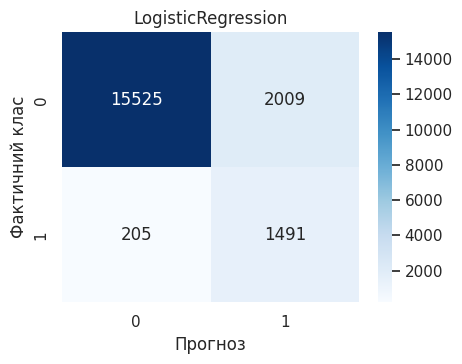

RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



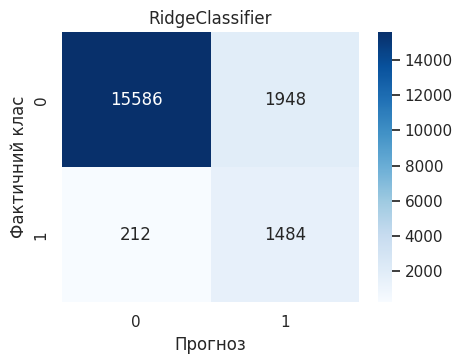

SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



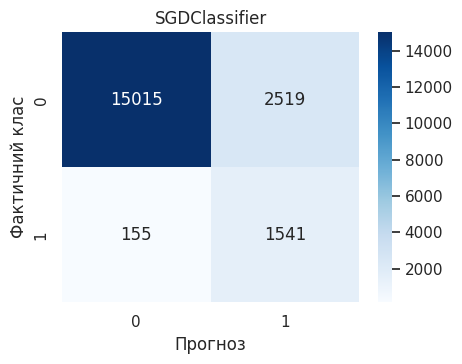

SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



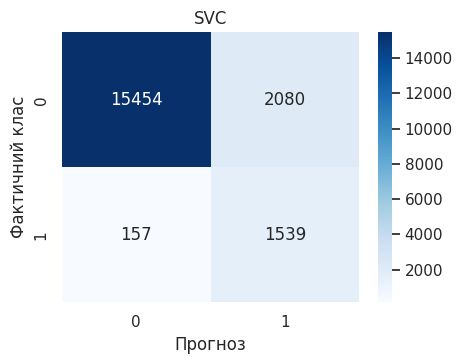

,F1,Recall,Precision,TN,FP,FN,TP
LogisticRegression,0.573903,0.879127,0.426000,15525.0,2009.0,205.0,1491.0
RidgeClassifier,0.578783,0.875000,0.432401,15586.0,1948.0,212.0,1484.0
SGDClassifier,0.535441,0.908608,0.379557,15015.0,2519.0,155.0,1541.0
SVC,0.579116,0.907429,0.425256,15454.0,2080.0,157.0,1539.0


In [31]:
baseline_results = {}
def evaluate(name, truth, pred, results):
    print(name)
    print(classification_report(truth,pred,labels=[0,1],zero_division=0))
    matrix = confusion_matrix(truth,pred,labels=[0,1])
    results[name] = {'F1':f1_score(truth,pred,zero_division=0),'Recall':recall_score(truth,pred,zero_division=0),'Precision':precision_score(truth,pred,zero_division=0),'TN':matrix[0,0],'FP':matrix[0,1],'FN':matrix[1,0],'TP':matrix[1,1]}
    fig,ax = plt.subplots(figsize=(4.8,3.8))
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',ax=ax,xticklabels=[0,1],yticklabels=[0,1])
    ax.set(xlabel='Прогноз',ylabel='Фактичний клас',title=name)
    plt.tight_layout(); plt.show()
for name, model in models.items():
    model.fit(X_train_balanced,y_train_balanced)
    evaluate(name,y_test,model.predict(X_test_scaled),baseline_results)
display(pd.DataFrame(baseline_results).T)

Оптимізувати гіперпараметри


In [32]:
param_grids = {
 'LogisticRegression': {'model__C':[0.1,1,10],'model__solver':['lbfgs','liblinear']},
 'RidgeClassifier': {'model__alpha':[0.1,1,10]},
 'SGDClassifier': {'model__loss':['hinge','log_loss'],'model__penalty':['l2','l1'],'model__alpha':[0.0001,0.001]},
 'SVC': {'model__C':[0.1,1,10],'model__kernel':['linear','rbf']}
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

LogisticRegression CV F1: 0.6413 Параметри: {'model__C': 10, 'model__solver': 'liblinear'}
LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



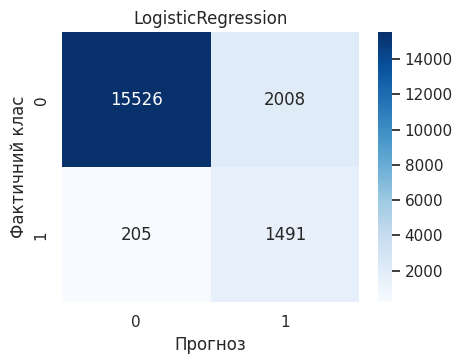

RidgeClassifier CV F1: 0.5222 Параметри: {'model__alpha': 1}
RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



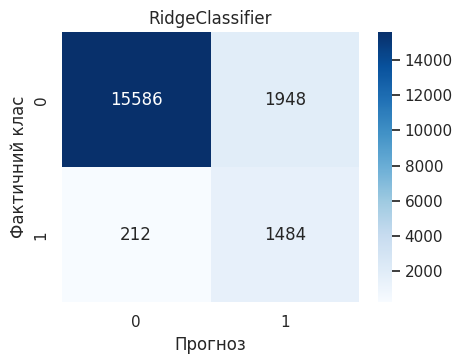

SGDClassifier CV F1: 0.6469 Параметри: {'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l1'}
SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



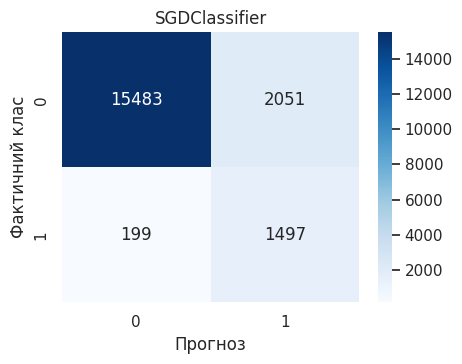

SVC CV F1: 0.6111 Параметри: {'model__C': 1, 'model__kernel': 'linear'}
SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



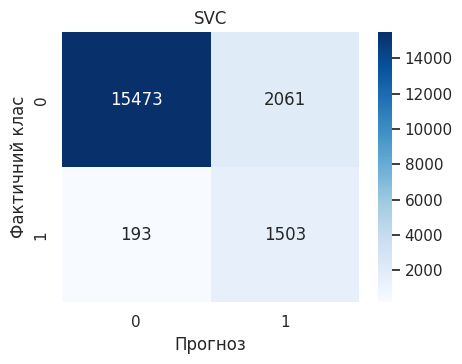

In [34]:
best_models, best_scores, best_params, optimized_results = {}, {}, {}, {}
cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
# Однаковий бюджет пошуку для всіх моделей; фінальний refit виконується на всьому train.
# Обмеження ресурсу зменшує час пошуку SVC на великому CSV.
max_resources = min(len(X_train), 3600)
for name, model in models.items():
    pipe = Pipeline([('scaler',StandardScaler()),('smote',SMOTE(random_state=42)),('model',clone(model))])
    search = HalvingGridSearchCV(pipe,param_grids[name],cv=cv,scoring='f1',min_resources=300,max_resources=max_resources,factor=2,random_state=42,n_jobs=1,error_score='raise')
    search.fit(X_train,y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    best_params[name] = search.best_params_
    print(name, 'CV F1:', round(search.best_score_,4), 'Параметри:', search.best_params_)
    evaluate(name,y_test,search.predict(X_test),optimized_results)

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
best_name = max(best_scores,key=best_scores.get)
best_model = best_models[best_name]
print('Найкраща модель за CV F1:',best_name,round(best_scores[best_name],4))
display(pd.Series(best_scores,name='CV F1').sort_values(ascending=False))

Найкраща модель за CV F1: SGDClassifier 0.6469


,CV F1
SGDClassifier,0.646942
LogisticRegression,0.641296
SVC,0.611071
RidgeClassifier,0.522222


In [36]:
sample = X_test.sample(n=10,random_state=42)
pred = best_model.predict(sample)
comparison = pd.DataFrame({'Індекс':sample.index,'Істинний клас':y_test.loc[sample.index].to_numpy(),'Передбачений клас':pred})
display(comparison)
assert len(comparison)==10 and X_test.index.equals(original_test_index) and y_test.equals(original_y_test)

,Індекс,Істинний клас,Передбачений клас
0,35493,0,0
1,29438,0,0
2,29287,0,1
3,11752,0,0
4,95450,0,0
5,26415,0,0
6,51899,0,0
7,67326,0,0
8,8881,0,1
9,36474,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Результати та висновки за фактичними метриками формуються нижче.

In [37]:
summary = pd.DataFrame(optimized_results).T
print('1. Баланс train:',y_train.value_counts().to_dict(),'; після SMOTE:',pd.Series(y_train_balanced).value_counts().to_dict())
print('Найсильніша кореляція з ціллю:',target_corr.index[0],round(target_corr.iloc[0],3),'; викиди за IQR:',outliers.to_dict(),'; не вилучалися.')
print('2. Найвищий тестовий F1:',summary['F1'].idxmax(),'; recall:',summary['Recall'].idxmax())
print('Вибір за CV:',best_name,round(best_scores[best_name],4))
print('3. Оптимальні параметри:',best_params)
display(summary)
print('FP — хибнопозитивні, FN — хибнонегативні. Для обраної моделі:',optimized_results[best_name])
print('4. Відкладений test забезпечує незалежну оцінку; scaler та SMOTE навчаються лише на train, у CV — окремо в кожному навчальному згині.')

1. Баланс train: {0: 70130, 1: 6786} ; після SMOTE: {0: 70130, 1: 70130}
Найсильніша кореляція з ціллю: blood_glucose_level 0.423 ; викиди за IQR: {'age': 0, 'bmi': 4244, 'HbA1c_level': 1041, 'blood_glucose_level': 1598} ; не вилучалися.
2. Найвищий тестовий F1: RidgeClassifier ; recall: SVC
Вибір за CV: SGDClassifier 0.6469
3. Оптимальні параметри: {'LogisticRegression': {'model__C': 10, 'model__solver': 'liblinear'}, 'RidgeClassifier': {'model__alpha': 1}, 'SGDClassifier': {'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l1'}, 'SVC': {'model__C': 1, 'model__kernel': 'linear'}}


,F1,Recall,Precision,TN,FP,FN,TP
LogisticRegression,0.574013,0.879127,0.426122,15526.0,2008.0,205.0,1491.0
RidgeClassifier,0.578783,0.875000,0.432401,15586.0,1948.0,212.0,1484.0
SGDClassifier,0.570938,0.882665,0.421928,15483.0,2051.0,199.0,1497.0
SVC,0.571483,0.886203,0.421717,15473.0,2061.0,193.0,1503.0


FP — хибнопозитивні, FN — хибнонегативні. Для обраної моделі: {'F1': 0.5709382151029748, 'Recall': 0.8826650943396226, 'Precision': 0.42192784667418265, 'TN': np.int64(15483), 'FP': np.int64(2051), 'FN': np.int64(199), 'TP': np.int64(1497)}
4. Відкладений test забезпечує незалежну оцінку; scaler та SMOTE навчаються лише на train, у CV — окремо в кожному навчальному згині.


**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

XGBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



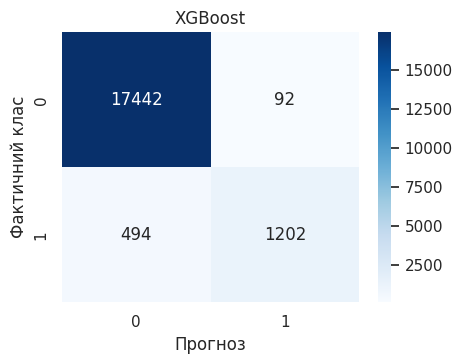

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



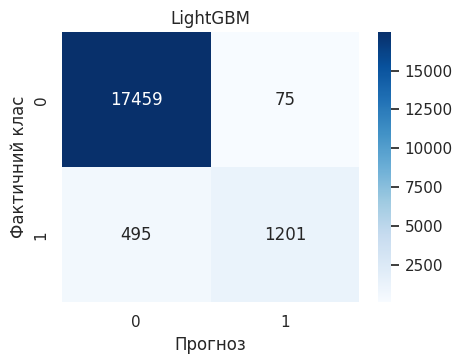

CatBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



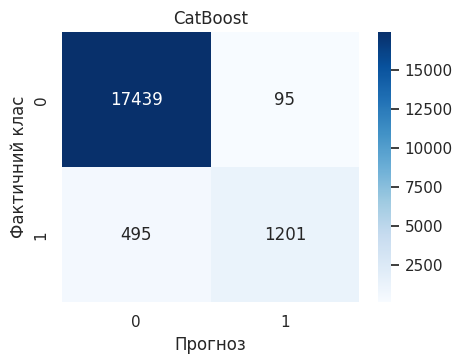

,F1,Recall,Precision,TN,FP,FN,TP
LightGBM,0.808210,0.708137,0.941223,17459.0,75.0,495.0,1201.0
XGBoost,0.804013,0.708726,0.928903,17442.0,92.0,494.0,1202.0
CatBoost,0.802807,0.708137,0.926698,17439.0,95.0,495.0,1201.0


Найвищий тестовий F1 серед додаткових моделей: LightGBM
Ці тестові метрики є описовими; вони не змінюють вибір основної моделі за CV.


In [38]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
extra_models = {
 'XGBoost': XGBClassifier(n_estimators=100,max_depth=4,random_state=42,n_jobs=2,eval_metric='logloss'),
 'LightGBM': LGBMClassifier(n_estimators=100,random_state=42,n_jobs=2,verbosity=-1),
 'CatBoost': CatBoostClassifier(iterations=100,depth=5,random_seed=42,verbose=False,thread_count=2,allow_writing_files=False)
}
extra_results = {}
for name,model in extra_models.items():
    model.fit(X_train_balanced,y_train_balanced)
    evaluate(name,y_test,model.predict(X_test_scaled).ravel(),extra_results)
extra_table = pd.DataFrame(extra_results).T.sort_values('F1',ascending=False)
display(extra_table)
print('Найвищий тестовий F1 серед додаткових моделей:',extra_table.index[0])
print('Ці тестові метрики є описовими; вони не змінюють вибір основної моделі за CV.')